In [1]:
# ---------------------------------------------------------
# Practical 3D: Machinery Fault Detection
# NASA Turbofan Engine Dataset using LSTM Autoencoder
# ---------------------------------------------------------

# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
# Step 2: Load the dataset

data = pd.read_csv("NASA TurboFan Engine.csv")

print("Dataset Shape:", data.shape)
print("\nFirst five records:")
print(data.head())

print("\nFault Label Distribution:")
print(data["Fault_Label"].value_counts())


Dataset Shape: (20631, 28)

First five records:
   unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0     1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1     1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2     1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3     1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4     1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   

   sensor4  sensor5  ...  sensor14  sensor15  sensor16  sensor17  sensor18  \
0  1400.60    14.62  ...   8138.62    8.4195      0.03       392      2388   
1  1403.14    14.62  ...   8131.49    8.4318      0.03       392      2388   
2  1404.20    14.62  ...   8133.23    8.4178      0.03       390      2388   
3  1401.87    14.62  ...   8133.83    8.3682      0.03       392      2388   
4  1406.22    14.62  ...   8133.80    8.4294      0.03       393      2388   

   sensor19  sensor20  sensor21 

In [3]:
# Step 3: Preprocess the data

# Sort by engine unit and operating cycle
data = data.sort_values(
    ["unit", "cycle"]
).reset_index(drop=True)


In [4]:
# Select sensor columns
sensor_columns = [
    col for col in data.columns
    if col.startswith("sensor")
]

In [5]:
# Remove constant sensor columns
sensor_columns = [
    col for col in sensor_columns
    if data[col].nunique() > 1
]

print("\nSelected Sensor Columns:")
print(sensor_columns)

print("\nNumber of selected sensors:", len(sensor_columns))



Selected Sensor Columns:
['sensor2', 'sensor3', 'sensor4', 'sensor6', 'sensor7', 'sensor8', 'sensor9', 'sensor11', 'sensor12', 'sensor13', 'sensor14', 'sensor15', 'sensor17', 'sensor20', 'sensor21']

Number of selected sensors: 15


In [6]:
# Handle missing values
data[sensor_columns] = data.groupby("unit")[
    sensor_columns
].transform(
    lambda group: group.interpolate(
        method="linear"
    ).ffill().bfill()
)

In [7]:
# Extract labels
data["Fault_Label"] = data["Fault_Label"].fillna(0)

In [8]:
# Step 4: Split data by engine units
# 70% training, 15% validation, 15% testing

unit_ids = data["unit"].unique()

np.random.seed(42)
np.random.shuffle(unit_ids)

train_end = int(len(unit_ids) * 0.70)
val_end = int(len(unit_ids) * 0.85)

train_units = unit_ids[:train_end]
val_units = unit_ids[train_end:val_end]
test_units = unit_ids[val_end:]

train_data = data[data["unit"].isin(train_units)].copy()
val_data = data[data["unit"].isin(val_units)].copy()
test_data = data[data["unit"].isin(test_units)].copy()

print("\nTraining Engines:", len(train_units))
print("Validation Engines:", len(val_units))
print("Testing Engines:", len(test_units))


Training Engines: 70
Validation Engines: 15
Testing Engines: 15


In [9]:
# Step 5: Normalize sensor readings

# Use only healthy training readings to fit the scaler
normal_train_rows = train_data[
    train_data["Fault_Label"] == 0
][sensor_columns]

scaler = MinMaxScaler()

scaler.fit(normal_train_rows)

,feature_range,"(0, ...)"
,copy,True
,clip,False


In [10]:
# Transform all three datasets
train_scaled = scaler.transform(
    train_data[sensor_columns]
)

val_scaled = scaler.transform(
    val_data[sensor_columns]
)

test_scaled = scaler.transform(
    test_data[sensor_columns]
)


In [11]:
# Step 6: Create time windows

TIME_STEPS = 30

def create_windows(dataset, scaled_data, time_steps):

    X_windows = []
    y_windows = []

    start = 0

    # Process each engine separately
    for unit_id, group in dataset.groupby("unit", sort=False):

        group_length = len(group)

        # Get the scaled readings for this engine
        engine_data = scaled_data[
            start:start + group_length
        ]

        # Get fault labels for this engine
        engine_labels = group["Fault_Label"].values

        # Create sequences of consecutive cycles
        for i in range(
            len(engine_data) - time_steps + 1
        ):

            X_windows.append(
                engine_data[i:i + time_steps]
            )

            # Label based on the final cycle of the window
            y_windows.append(
                engine_labels[i + time_steps - 1]
            )

        start += group_length

    return np.array(X_windows), np.array(y_windows)


In [12]:
# Create windows for training data
X_train_windows, y_train_windows = create_windows(
    train_data,
    train_scaled,
    TIME_STEPS
)


In [13]:
# Create windows for validation data
X_val_windows, y_val_windows = create_windows(
    val_data,
    val_scaled,
    TIME_STEPS
)


In [14]:
# Create windows for testing data
X_test_windows, y_test_windows = create_windows(
    test_data,
    test_scaled,
    TIME_STEPS
)

In [15]:
# Keep only completely healthy training windows
# The final cycle label is 0 for a healthy window
X_train_normal = X_train_windows[
    y_train_windows == 0
]

In [16]:
# Keep only healthy validation windows
X_val_normal = X_val_windows[
    y_val_windows == 0
]

print("\nTraining Window Shape:", X_train_normal.shape)
print("Validation Window Shape:", X_val_normal.shape)
print("Testing Window Shape:", X_test_windows.shape)


Training Window Shape: (10116, 30, 15)
Validation Window Shape: (2270, 30, 15)
Testing Window Shape: (2710, 30, 15)


In [17]:
# Step 7: Build LSTM Autoencoder

input_shape = (
    TIME_STEPS,
    len(sensor_columns)
)

model = keras.Sequential([

    # Encoder
    layers.Input(shape=input_shape),

    layers.LSTM(
        64,
        activation="tanh",
        return_sequences=True
    ),

    layers.LSTM(
        32,
        activation="tanh",
        return_sequences=False
    ),

    # Repeat compressed representation
    layers.RepeatVector(TIME_STEPS),

    # Decoder
    layers.LSTM(
        32,
        activation="tanh",
        return_sequences=True
    ),

    layers.LSTM(
        64,
        activation="tanh",
        return_sequences=True
    ),

    # Reconstruct sensor readings
    layers.TimeDistributed(
        layers.Dense(len(sensor_columns))
    )
])

In [18]:
# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 30, 64)              │          20,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 30, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 30, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 30, 64)              │          24,832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 30, 15)              │             975 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 67,023 (261.81 KB)

 Trainable params: 67,023 (261.81 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Step 8: Compile the model

model.compile(
    optimizer="adam",
    loss="mse"
)

In [20]:
# Step 9: Train using healthy engine sequences

history = model.fit(
    X_train_normal,
    X_train_normal,

    epochs=20,
    batch_size=64,

    validation_data=(
        X_val_normal,
        X_val_normal
    ),

    shuffle=True
)


Epoch 1/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - loss: 0.0301 - val_loss: 0.0106
Epoch 2/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 47ms/step - loss: 0.0099 - val_loss: 0.0095
Epoch 3/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - loss: 0.0094 - val_loss: 0.0094
Epoch 4/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - loss: 0.0084 - val_loss: 0.0084
Epoch 5/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - loss: 0.0080 - val_loss: 0.0083
Epoch 6/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - loss: 0.0080 - val_loss: 0.0084
Epoch 7/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 50ms/step - loss: 0.0079 - val_loss: 0.0083
Epoch 8/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - loss: 0.0079 - val_loss: 0.0083
Epoch 9/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - loss: 0.0079 - val_loss: 0.0082
Epoch 10/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 11s 54ms/step - loss: 0.0079 - val_loss: 0.0082
Epoch 11/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - loss: 0.0079 - val_loss: 0.0083
Epoch 12/20
159/159 ━━━━━━━━━━━━━━━

In [21]:
# Step 10: Calculate reconstruction error
# Use healthy validation windows to set threshold

val_reconstructed = model.predict(X_val_normal)

val_errors = np.mean(
    np.square(X_val_normal - val_reconstructed),
    axis=(1, 2)
)

71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step


In [22]:
# Set threshold using 99th percentile
threshold = np.percentile(val_errors, 99)

print("\nFault Detection Threshold:", threshold)



Fault Detection Threshold: 0.017367756881582735


In [23]:
# Step 11: Detect faults in test data

test_reconstructed = model.predict(X_test_windows)

test_errors = np.mean(
    np.square(X_test_windows - test_reconstructed),
    axis=(1, 2)
)

85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step


In [24]:
# Classify high reconstruction error as fault
y_pred = (test_errors > threshold).astype(int)

In [25]:
# Step 12: Evaluate the model

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_windows, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test_windows,
        y_pred,
        zero_division=0
    )
)

print("Precision:", precision_score(
    y_test_windows, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test_windows, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test_windows, y_pred, zero_division=0
))



Confusion Matrix:
[[2243    2]
 [ 449   16]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91      2245
           1       0.89      0.03      0.07       465

    accuracy                           0.83      2710
   macro avg       0.86      0.52      0.49      2710
weighted avg       0.84      0.83      0.76      2710

Precision: 0.8888888888888888
Recall: 0.034408602150537634
F1 Score: 0.06625258799171843


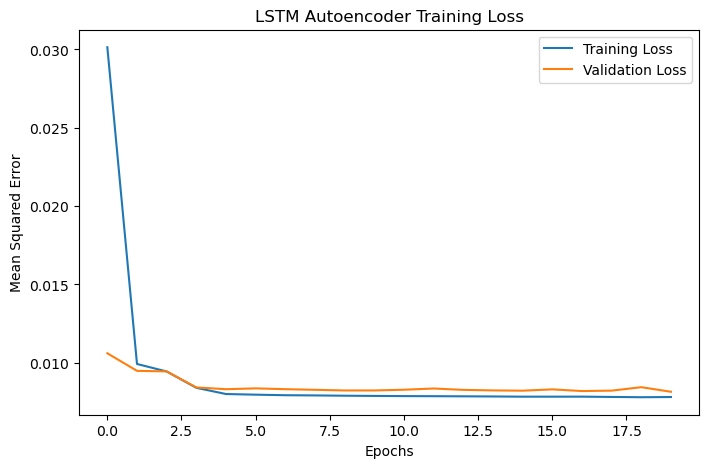

In [26]:
# Step 13: Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.show()


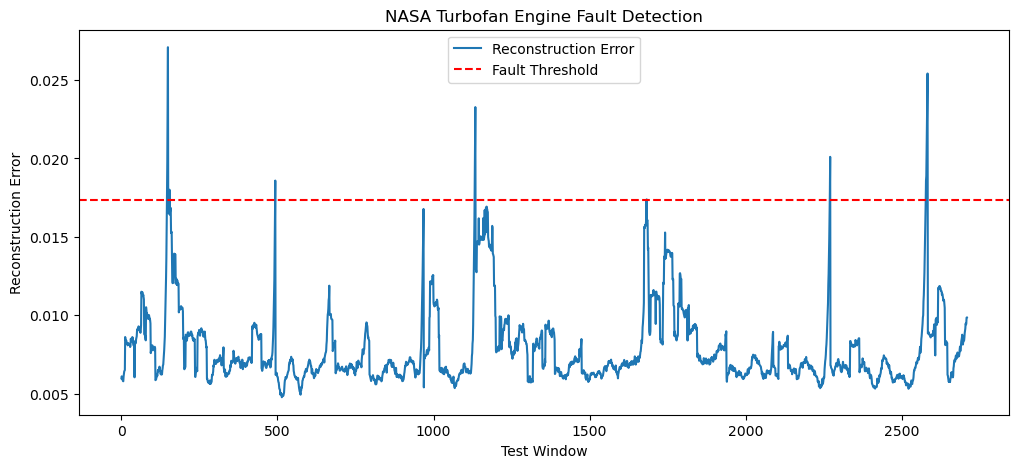

In [27]:
# Step 14: Plot reconstruction error and threshold

plt.figure(figsize=(12, 5))

plt.plot(
    test_errors,
    label="Reconstruction Error"
)

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Fault Threshold"
)

plt.title("NASA Turbofan Engine Fault Detection")
plt.xlabel("Test Window")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()

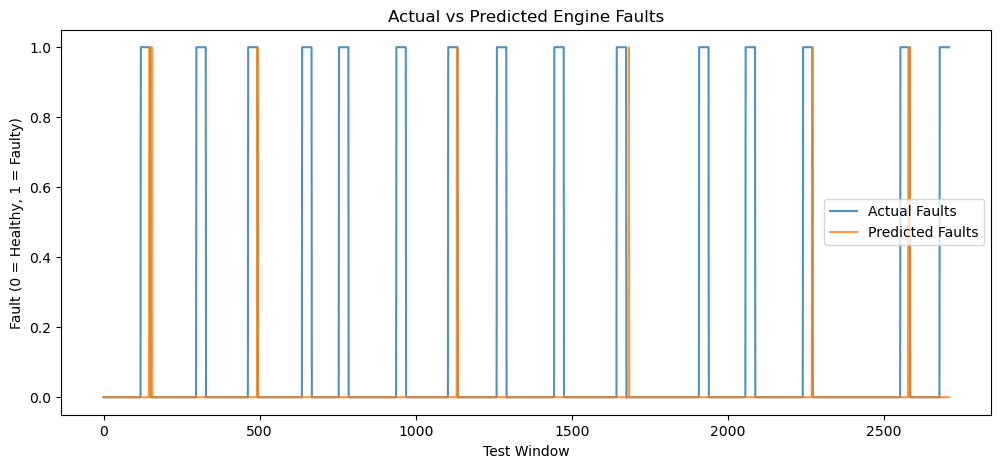

In [28]:
# Step 15: Compare actual and predicted faults

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_windows,
    label="Actual Faults",
    alpha=0.8
)

plt.plot(
    y_pred,
    label="Predicted Faults",
    alpha=0.8
)

plt.title("Actual vs Predicted Engine Faults")
plt.xlabel("Test Window")
plt.ylabel("Fault (0 = Healthy, 1 = Faulty)")
plt.legend()
plt.show()


In [29]:
# Step 16: Display final results

print("\nTotal Test Windows:", len(y_test_windows))
print("Actual Fault Windows:", np.sum(y_test_windows))
print("Predicted Fault Windows:", np.sum(y_pred))

print("\nPractical Completed Successfully!")



Total Test Windows: 2710
Actual Fault Windows: 465
Predicted Fault Windows: 18

Practical Completed Successfully!
